# Delta Lake with Spark (delta-spark)

M12 Lesson 04 used Delta Lake from Python with `deltalake` (delta-rs). Delta Lake started in Spark, and Spark is
still its most complete engine: SQL `MERGE INTO`, `RESTORE`, `OPTIMIZE ... ZORDER BY`, constraints and the Change
Data Feed all run as distributed Spark jobs. This lesson builds a Delta table of taxi trips with **delta-spark** and
uses these features one by one, with measurements. At the end, two other engines read the same table.

**After this lesson you can:**

1. Create a partitioned Delta table with Spark and read its history and transaction log.
2. Apply upserts and deletes with `MERGE INTO` (SQL) and the `DeltaTable` Python API; use time travel and `RESTORE`.
3. Use schema enforcement, schema evolution and `CHECK` constraints.
4. Measure the effect of `OPTIMIZE ... ZORDER BY` on files read, use `VACUUM`, and read the Change Data Feed.

**Data:** NYC taxi trips of 2024-01-01 to 2024-01-14 (about 1.3 million rows), plus trips of 2024-01-15 as "new" data.
**Services:** none (Spark runs locally in the notebook).

In [1]:
import json
import shutil
import sys
import tempfile
import time
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from delta import configure_spark_with_delta_pip
from delta.tables import DeltaTable
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
WORK = Path(tempfile.gettempdir()) / "fzth-m13" / "l09"
shutil.rmtree(WORK, ignore_errors=True); WORK.mkdir(parents=True)
PATH = WORK / "trips"                             # the Delta table folder

builder = (SparkSession.builder.master("local[4]").appName("m13-l09")
           .config("spark.driver.memory", "1500m").config("spark.sql.shuffle.partitions", "8")
           .config("spark.ui.showConsoleProgress", "false").config("spark.sql.session.timeZone", "UTC")
           .config("spark.driver.extraJavaOptions", "-Duser.timezone=UTC")   # one time zone for Delta commit times
           .config("spark.sql.warehouse.dir", str(WORK / "warehouse"))
           .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
           .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog"))
spark = configure_spark_with_delta_pip(builder).getOrCreate()     # adds the delta-spark jars (cached by Ivy)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| delta-spark", __import__("importlib.metadata").metadata.version("delta-spark"))

COLS = ["trip_id", "pickup_date", "tpep_pickup_datetime", "PULocationID", "DOLocationID", "passenger_count",
        "trip_distance", "fare_amount", "tip_amount", "total_amount"]
jan = (spark.read.parquet(str(datasets.taxi("2024-01")))
       .withColumn("pickup_date", F.to_date("tpep_pickup_datetime"))
       .withColumn("trip_id", F.monotonically_increasing_id())       # stored once, so it stays stable
       .withColumn("passenger_count", F.col("passenger_count").cast("int")))
first14 = jan.where("pickup_date BETWEEN '2024-01-01' AND '2024-01-14'").select(COLS)
day15 = jan.where("pickup_date = '2024-01-15'").select(COLS)

def log_files() -> list[str]:
    return sorted(p.name for p in (PATH / "_delta_log").iterdir() if p.is_file())

def history(n: int = 20) -> pd.DataFrame:
    return (spark.sql(f"DESCRIBE HISTORY trips LIMIT {n}")
            .select("version", "operation", "operationMetrics").toPandas().sort_values("version"))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/24 18:57:34 WARN Utils: Your hostname, Muhammet, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/24 18:57:34 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


:: loading settings :: url = jar:file:/mnt/d/MuhammetAliVarlik/PythonProjects/FromZeroToHero-DataScience-AI-Cloud/FromZeroToHero-DataScience-AI-Cloud/.venv/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-7efd40b1-3d35-45cb-8575-a9b8a6252bab;1.0
	confs: [default]


	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central


	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central


	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found org.roaringbitmap#RoaringBitmap;0.9.25 in central
	found com.fasterxml.jackson.core#jackson-databind;2.13.5 in central


... (2 outputs left out)

	found io.airlift#aircompressor;2.0.2 in central
	found commons-pool#commons-pool;1.6 in central
	found com.github.luben#zstd-jni;1.5.7-3 in central
	found org.apache.hadoop#hadoop-client-api;3.4.2 in central
	found commons-logging#commons-logging;1.3.0 in central
	found org.apache.parquet#parquet-jackson;1.16.0 in central
	found io.delta#delta-kernel-unitycatalog;4.4.1 in central
:: resolution report :: resolve 1651ms :: artifacts dl 18ms
	:: modules in use:
	com.fasterxml.jackson.core#jackson-annotations;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-core;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-databind;2.13.5 from central in [default]
	com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 from central in [default]
	com.github.luben#zstd-jni;1.5.7-3 from central in [default]
	com.google.code.findbugs#jsr305;3.0.2 from central in [default]
	commons-logging#commons-logging;1.3.0 from central in [default]
	commons-pool#commons-poo

26/11/24 18:57:36 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 4.2.0 | delta-spark 4.4.1


## 1. Create a Partitioned Delta Table

`format("delta")` writes Parquet files plus a JSON commit in `_delta_log/`. `partitionBy("pickup_date")` puts each
day in its own folder. `repartition(8, "trip_id")` before the write gives 8 files per day: small files on purpose,
for the `OPTIMIZE` section. `saveAsTable` with a `path` registers the folder as table `trips` in the Spark catalog,
so SQL can use the name.

In [2]:
t0 = time.perf_counter()
(first14.repartition(8, "trip_id").write.format("delta").partitionBy("pickup_date")
 .option("path", str(PATH)).saveAsTable("trips"))
print(f"write: {time.perf_counter() - t0:.1f} s")

detail = spark.sql("DESCRIBE DETAIL trips").select("format", "partitionColumns", "numFiles", "sizeInBytes",
                                                  "minReaderVersion", "minWriterVersion").toPandas()
print(detail.to_string(index=False))
print("rows:", spark.table("trips").count())
print("partition folders:", len([p for p in PATH.iterdir() if p.name.startswith("pickup_date=")]),
      "| log files:", log_files())

commit0 = [json.loads(l) for l in (PATH / "_delta_log" / "00000000000000000000.json").read_text().splitlines()]
actions = pd.Series([next(iter(a)) for a in commit0]).value_counts()
print("actions in commit 0:", actions.to_dict())
add = next(a["add"] for a in commit0 if "add" in a)
stats = json.loads(add["stats"])
print("one add action:", add["path"], "| numRecords:", stats["numRecords"],
      "| PULocationID min/max:", stats["minValues"]["PULocationID"], stats["maxValues"]["PULocationID"])

write: 9.6 s


format partitionColumns  numFiles  sizeInBytes  minReaderVersion  minWriterVersion
 delta    [pickup_date]       112     25918425                 3                 7


rows: 1286537
partition folders: 14 | log files: ['.00000000000000000000.crc.crc', '.00000000000000000000.json.crc', '00000000000000000000.crc', '00000000000000000000.json']
actions in commit 0: {'add': 112, 'commitInfo': 1, 'metaData': 1, 'protocol': 1}
one add action: pickup_date=2024-01-01/part-00000-27cb58d5-f8a0-4dc6-9918-6600514e8def.c000.snappy.parquet | numRecords: 10095 | PULocationID min/max: 1 265


*Insight: One commit file describes the whole table: the schema (`metaData`), the protocol version, and one `add`
action per data file with row count and min/max statistics per column. These statistics enable file skipping later.*

## 2. MERGE INTO: Upserts and Deletes

A **change set** arrives from the source system: corrected fares, trips that must be deleted, and new trips.
`MERGE INTO` applies all of them in **one** atomic commit. Delta finds the files that contain matching rows,
rewrites only those files, and adds the new rows.

First with SQL:

In [3]:
corrections = (spark.table("trips").where("trip_id % 1400 = 0")
               .withColumn("fare_amount", F.col("fare_amount") + 2.5)
               .withColumn("total_amount", F.col("total_amount") + 2.5).withColumn("op", F.lit("U")))
deletes = spark.table("trips").where("trip_id % 2800 = 7").withColumn("op", F.lit("D"))
new_trips = day15.where("trip_id % 10 = 0").withColumn("op", F.lit("I"))
changes = corrections.unionByName(deletes).unionByName(new_trips)
changes.createOrReplaceTempView("changes")
print(changes.groupBy("op").count().orderBy("op").toPandas().to_string(index=False))

before = spark.table("trips").count()
insert_cols = ", ".join(COLS)
spark.sql(f"""
MERGE INTO trips AS t
USING changes AS s
ON t.trip_id = s.trip_id
WHEN MATCHED AND s.op = 'D' THEN DELETE
WHEN MATCHED AND s.op = 'U' THEN UPDATE SET t.fare_amount = s.fare_amount, t.total_amount = s.total_amount
WHEN NOT MATCHED AND s.op = 'I' THEN INSERT ({insert_cols}) VALUES ({", ".join("s." + c for c in COLS)})
""")
after = spark.table("trips").count()
m = history().iloc[-1]
print(f"rows: {before:,} -> {after:,} (change {after - before:+,})")
print({k: m.operationMetrics[k] for k in ["numTargetRowsUpdated", "numTargetRowsDeleted", "numTargetRowsInserted",
                                          "numTargetFilesRemoved", "numTargetFilesAdded"]})

op  count
 D    459
 I   7705
 U    918


rows: 1,286,537 -> 1,293,783 (change +7,246)
{'numTargetRowsUpdated': '918', 'numTargetRowsDeleted': '459', 'numTargetRowsInserted': '7705', 'numTargetFilesRemoved': '112', 'numTargetFilesAdded': '15'}


The same operation with the **`DeltaTable` Python API**: here a second correction run updates the tips of some
trips and inserts the rest of 2024-01-15. `whenNotMatchedInsertAll()` copies all columns by name.

In [4]:
dt = DeltaTable.forName(spark, "trips")
tip_fix = spark.table("trips").where("trip_id % 3000 = 1").withColumn("tip_amount", F.col("tip_amount") + 1.0)
rest15 = day15.where("trip_id % 10 != 0")
source = tip_fix.unionByName(rest15)

before = spark.table("trips").count()
metrics = (dt.alias("t").merge(source.alias("s"), "t.trip_id = s.trip_id")
           .whenMatchedUpdate(set={"tip_amount": "s.tip_amount"})
           .whenNotMatchedInsertAll()
           .execute())
print(metrics.toPandas().to_string(index=False))
print(f"rows: {before:,} -> {spark.table('trips').count():,}")
print(history()[["version", "operation"]].to_string(index=False))

 num_affected_rows  num_updated_rows  num_deleted_rows  num_inserted_rows
             69757               429                 0              69328


rows: 1,293,783 -> 1,363,111


 version              operation
       0 CREATE TABLE AS SELECT
       1                  MERGE
       2                  MERGE


*Insight: Both merges are single commits (versions 1 and 2). The first merge changed 1,377 trips (918 updates, 459
deletes) spread over all 14 days. So it rewrote all 112 files: it removed 112 files and added 15. A merge condition that includes the partition column
(`t.pickup_date = s.pickup_date`) lets Delta skip whole partitions and rewrite less.*

## 3. Time Travel and RESTORE

Every version stays readable until `VACUUM` removes its files. `VERSION AS OF` and `TIMESTAMP AS OF` read an old
version. `RESTORE` makes an old version the current one again, as a **new** commit (history is never rewritten).
The cell simulates a mistake: a `DELETE` with a wrong condition removes all JFK pickups (zone 132).

In [5]:
spark.sql("DELETE FROM trips WHERE PULocationID = 132")           # the mistake: version 3
# commit time of version 1 as text in the session time zone (UTC), ready for a SQL literal
ts_v1 = (spark.sql("DESCRIBE HISTORY trips").where("version = 1")
         .select(F.date_format("timestamp", "yyyy-MM-dd HH:mm:ss.SSS")).first()[0])

def count_at(clause: str) -> int:
    return spark.sql(f"SELECT count(*) AS n FROM trips {clause}").first().n

print(f"current (v3, after the bad delete): {count_at(''):,}")
print(f"VERSION AS OF 2:                    {count_at('VERSION AS OF 2'):,}")
print(f"TIMESTAMP AS OF '{ts_v1}' (v1): {count_at(f"TIMESTAMP AS OF '{ts_v1}'"):,}")
print(f"VERSION AS OF 0:                    {count_at('VERSION AS OF 0'):,}")
lost = spark.sql("SELECT count(*) AS n FROM trips VERSION AS OF 2 WHERE PULocationID = 132").first().n
print(f"JFK trips lost by the mistake: {lost:,}")

restore = spark.sql("RESTORE TABLE trips TO VERSION AS OF 2").toPandas()
print(restore[["num_restored_files", "num_removed_files", "restored_files_size"]].to_string(index=False))
print(f"after RESTORE (v4): {count_at(''):,} rows")

current (v3, after the bad delete): 1,285,918


VERSION AS OF 2:                    1,363,111


TIMESTAMP AS OF '2026-11-24 18:58:19.147' (v1): 1,293,783


VERSION AS OF 0:                    1,286,537


JFK trips lost by the mistake: 77,193


 num_restored_files  num_removed_files  restored_files_size
                 16                 15             25581691


after RESTORE (v4): 1,363,111 rows


*Insight: The restore did not copy data. It wrote a commit that removes the files of version 3 and adds the files
of version 2 back to the table, so it takes seconds even for large tables.*

## 4. Schema Enforcement, Evolution and Constraints

- **Schema enforcement:** a write with a column the table does not have fails. Bad data never enters silently.
- **Schema evolution:** with `mergeSchema`, the write adds the new column. Old rows read it as `NULL`.
- **Constraints:** `CHECK` constraints are stored in the table and checked on every write, by every Delta writer.

In [6]:
extra = day15.limit(5).withColumn("trip_id", F.col("trip_id") + 50_000_000).withColumn("dispatch_note", F.lit("app"))
try:
    extra.write.format("delta").mode("append").saveAsTable("trips")
except Exception as e:
    print("rejected:", type(e).__name__, "|", str(e).splitlines()[0][:120])

extra.write.format("delta").mode("append").option("mergeSchema", "true").saveAsTable("trips")
print("columns now:", spark.table("trips").columns[-3:])
print(spark.sql("SELECT dispatch_note, count(*) AS n FROM trips GROUP BY dispatch_note").toPandas().to_string(index=False))

rejected: AnalysisException | [DELTA_METADATA_MISMATCH] A metadata mismatch was detected when writing to the Delta table.


columns now: ['tip_amount', 'total_amount', 'dispatch_note']


dispatch_note       n
          NaN 1363111
          app       5


In [7]:
negative = spark.sql("SELECT count(*) AS n FROM trips WHERE fare_amount < 0").first().n
try:
    spark.sql("ALTER TABLE trips ADD CONSTRAINT fare_not_negative CHECK (fare_amount >= 0)")
except Exception as e:
    print(f"rejected while {negative:,} rows violate it:", type(e).__name__)

spark.sql("DELETE FROM trips WHERE fare_amount < 0")                # clean the existing data first
spark.sql("ALTER TABLE trips ADD CONSTRAINT fare_not_negative CHECK (fare_amount >= 0)")
print("constraint added; table property:",
      spark.sql("SHOW TBLPROPERTIES trips").where("key LIKE 'delta.constraints%'").toPandas().values.tolist())

bad = day15.limit(1).withColumn("trip_id", F.lit(90_000_000).cast("long")).withColumn("fare_amount", F.lit(-5.0))
spark.sparkContext.setLogLevel("OFF")        # the executor logs the expected rejection as a stack trace; hide it
try:
    bad.write.format("delta").mode("append").saveAsTable("trips")
except Exception as e:
    print("bad write rejected:", type(e).__name__, "|", str(e).splitlines()[0][:110])
finally:
    spark.sparkContext.setLogLevel("ERROR")      # the level of the setup cell
print("rows with negative fare now:", spark.sql("SELECT count(*) AS n FROM trips WHERE fare_amount < 0").first().n)

rejected while 17,640 rows violate it: AnalysisException


constraint added; table property: [['delta.constraints.fare_not_negative', 'fare_amount >= 0']]


bad write rejected: Py4JJavaError | An error occurred while calling o359.saveAsTable.


rows with negative fare now: 0


*Insight: The constraint could only be added after the old violations were removed, and after that the bad write
failed as a whole: no partial commit. Constraints belong to the table, so the rule holds for every job that writes it.*

## 5. OPTIMIZE, ZORDER BY and VACUUM

The first write made 8 files per day (112 files). The first merge rewrote them into one file per day, so the table
now has 16 files of about 1.6 MB each, and every file holds all pickup zones of its day. `OPTIMIZE` compacts small
files into larger ones. `ZORDER BY (PULocationID)` also sorts the rows of
each partition by pickup zone before writing. Then each file covers a narrow range of zones, and its min/max
statistics let a query on one zone skip most files (**data skipping**).

Data skipping needs several files per partition. The target file size of `OPTIMIZE` is 1 GB by default, larger
than a whole day here. The cell sets it to 128 KB, so each day gets about 12 files, as a large table with 1 GB
files would have. The files and bytes read come from the `numFiles` and `filesSize` metrics of the scan node in the
executed plan (the Spark UI shows them as "number of files read" and "size of files read").

In [8]:
def scan_stats(sql: str) -> tuple[int, float, float]:
    """Run a query twice; return the files and MB read by its table scan (scan metrics) and the best time."""
    spark.conf.set("spark.sql.adaptive.enabled", "false")      # a plain physical plan: easy to walk
    best = 1e9
    for _ in range(2):
        df = spark.sql(sql)
        t0 = time.perf_counter(); df.collect(); best = min(best, time.perf_counter() - t0)
    leaves = df._jdf.queryExecution().executedPlan().collectLeaves()
    scans = [leaves.apply(i) for i in range(leaves.size()) if leaves.apply(i).nodeName().startswith("Scan")]
    files = sum(int(s.metrics().apply("numFiles").value()) for s in scans)
    mb = sum(int(s.metrics().apply("filesSize").value()) for s in scans) / 1e6
    spark.conf.set("spark.sql.adaptive.enabled", "true")
    return files, mb, best

QUERY = "SELECT count(*), round(sum(total_amount), 2) FROM trips WHERE PULocationID = 132"
files_before = spark.sql("DESCRIBE DETAIL trips").first().numFiles
read_before, mb_before, sec_before = scan_stats(QUERY)
answer_before = spark.sql(QUERY).first()

spark.conf.set("spark.databricks.delta.optimize.maxFileSize", str(128 * 1024))   # 128 KB target: many files per day
opt = spark.sql("OPTIMIZE trips ZORDER BY (PULocationID)").first().metrics
files_after = spark.sql("DESCRIBE DETAIL trips").first().numFiles
read_after, mb_after, sec_after = scan_stats(QUERY)
print(f"OPTIMIZE: files removed {opt.numFilesRemoved}, files added {opt.numFilesAdded}")
print(f"before: zone 132 reads {read_before} of {files_before} files, {mb_before:.1f} MB")
print(f"after:  zone 132 reads {read_after} of {files_after} files, {mb_after:.1f} MB")
print(f"query: {sec_before * 1000:.0f} ms -> {sec_after * 1000:.0f} ms (best of 2)")
print("same answer:", tuple(answer_before) == tuple(spark.sql(QUERY).first()))

OPTIMIZE: files removed 16, files added 185
before: zone 132 reads 16 of 16 files, 25.2 MB
after:  zone 132 reads 24 of 185 files, 3.9 MB
query: 319 ms -> 404 ms (best of 2)


same answer: True


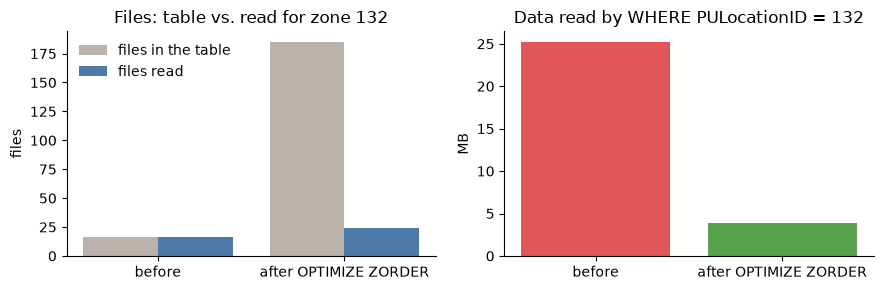

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
labels = ["before", "after OPTIMIZE ZORDER"]
x = range(2)
ax[0].bar([i - 0.2 for i in x], [files_before, files_after], width=0.4, color="#BAB0AC", label="files in the table")
ax[0].bar([i + 0.2 for i in x], [read_before, read_after], width=0.4, color="#4E79A7", label="files read")
ax[0].set(title="Files: table vs. read for zone 132", ylabel="files", xticks=list(x), xticklabels=labels)
ax[0].legend(frameon=False)
ax[1].bar(labels, [mb_before, mb_after], color=["#E15759", "#59A14F"])
ax[1].set(title="Data read by WHERE PULocationID = 132", ylabel="MB")
plt.tight_layout(); plt.show()

`OPTIMIZE` does not delete the old files: old versions still need them for time travel. **`VACUUM`** deletes files
that no current version needs and that are older than the retention period (default **7 days**). The retention
period protects two groups: readers that still read an older version, and writers whose transaction started
earlier. A shorter period can break them, so Delta refuses `RETAIN 0 HOURS` unless the safety check is disabled.
The demo disables it; never do this on a shared table.

In [10]:
def parquet_on_disk() -> int:
    return sum(1 for p in PATH.rglob("*.parquet") if "_delta_log" not in p.parts)

on_disk_before = parquet_on_disk()
try:
    spark.sql("VACUUM trips RETAIN 0 HOURS")
except Exception as e:
    print("refused:", type(e).__name__, "|", str(e).splitlines()[0][:100])

spark.conf.set("spark.databricks.delta.retentionDurationCheck.enabled", "false")   # demo only
spark.sql("VACUUM trips RETAIN 0 HOURS")
print(f"parquet files on disk: {on_disk_before} -> {parquet_on_disk()} "
      f"(current version: {spark.sql('DESCRIBE DETAIL trips').first().numFiles})")
try:
    spark.sql("SELECT count(*) FROM trips VERSION AS OF 0").collect()
except Exception as e:
    print("time travel to version 0 now fails:", type(e).__name__)

refused: IllegalArgumentException | [DELTA_VACUUM_RETENTION_PERIOD_TOO_SHORT] The specified VACUUM retention period is too low and may c


Deleted 173 files and directories in a total of 16 directories.


parquet files on disk: 358 -> 185 (current version: 185)


*Insight: Before `OPTIMIZE`, the query for zone 132 read all 16 files (25.2 MB), because every file held all zones.
After Z-ordering, it read 24 of 185 files (3.9 MB, about 1.6 files per day). Each file now holds a narrow
range of zones. The query was not faster here (319 ms before, 404 ms after): in local mode, opening 24 small files
costs more than the 21.3 MB that Spark did not read. On a large table, data skipping saves gigabytes of reads. VACUUM removed the old files, and with them the time travel to old versions: retention is the time-travel
window you pay for in storage.*

## 6. Change Data Feed

With `delta.enableChangeDataFeed = true`, Delta records row-level changes of every later commit. Downstream jobs
read only the changes (inserts, deletes, and update pre/post images) instead of the whole table: for example to
update a gold table or to send changes to a search index.

In [11]:
spark.sql("ALTER TABLE trips SET TBLPROPERTIES (delta.enableChangeDataFeed = true)")
cdf_start = int(spark.sql("DESCRIBE HISTORY trips LIMIT 1").first().version) + 1
spark.sql("UPDATE trips SET tip_amount = tip_amount + 1 WHERE pickup_date = '2024-01-03' AND PULocationID = 161")
spark.sql("DELETE FROM trips WHERE pickup_date = '2024-01-04' AND PULocationID = 1")
day15.where("trip_id % 10 = 0").limit(50).withColumn("trip_id", F.col("trip_id") + 70_000_000) \
    .write.format("delta").mode("append").saveAsTable("trips")

changes = spark.sql(f"SELECT * FROM table_changes('trips', {cdf_start})")
summary = changes.groupBy("_commit_version", "_change_type").count().orderBy("_commit_version", "_change_type")
print(summary.toPandas().to_string(index=False))
one = changes.where("_change_type LIKE 'update%'").orderBy("trip_id", "_change_type").limit(2)
print(one.select("trip_id", "_change_type", "tip_amount", "_commit_version").toPandas().to_string(index=False))
print("files in _change_data/:", sum(1 for _ in (PATH / "_change_data").rglob("*.parquet"))
      if (PATH / "_change_data").exists() else 0)

 _commit_version     _change_type  count
              12 update_postimage   4365
              12  update_preimage   4365
              13           delete     10
              14           insert     50


 trip_id     _change_type  tip_amount  _commit_version
  143881 update_postimage         1.0               12
  143881  update_preimage         0.0               12
files in _change_data/: 3


*Insight: The update wrote a pre-image and a post-image for every changed row, the delete wrote one row per deleted
trip, and the append wrote its inserts. A consumer that remembers the last version it read can process only new
changes, without comparing full tables.*

## 7. Interoperability: delta-rs and DuckDB

The table is open: a folder of Parquet files and a log. Any engine that implements the Delta protocol can read it,
without Spark. The cell reads the current version with `deltalake` (delta-rs, M12 Lesson 04) and with DuckDB's
`delta` extension (installed by DuckDB on first use, then cached).

In [12]:
from deltalake import DeltaTable as RsDeltaTable

spark_count = spark.table("trips").count()
rs = RsDeltaTable(str(PATH))
proto = rs.protocol()
print(f"Spark: {spark_count:,} rows | delta-rs: {rs.to_pyarrow_dataset().count_rows():,} rows, version {rs.version()}, "
      f"protocol reader {proto.min_reader_version} / writer {proto.min_writer_version}, "
      f"writer features {proto.writer_features}")

con = duckdb.connect()
try:
    con.sql("INSTALL delta"); con.sql("LOAD delta")
    n, jfk = con.sql(f"SELECT count(*), count(*) FILTER (WHERE PULocationID = 132) FROM delta_scan('{PATH}')").fetchone()
    print(f"DuckDB delta_scan: {n:,} rows, {jfk:,} JFK pickups")
except Exception as e:
    print("DuckDB delta extension not available:", type(e).__name__, str(e)[:100])

Spark: 1,345,516 rows | delta-rs: 1,345,516 rows, version 14, protocol reader 3 / writer 7, writer features ['checkConstraints', 'timestampNtz', 'invariants', 'changeDataFeed', 'appendOnly']


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

DuckDB delta_scan: 1,345,516 rows, 75,193 JFK pickups


*Insight: Three engines (Spark, delta-rs, DuckDB) read the same table and agree on the row count. The table
features that Spark enabled (constraints, Change Data Feed) are writer features, so readers that do not know them
can still read the table.*

## Real-World Use Case or Analogy

A Delta table is like a **shared ledger** in an accounting office. Nobody erases a line: a correction is a new entry
(MERGE), a mistake is undone with a reversing entry (RESTORE), and an auditor can see the books as they were on any
date (time travel). Old paper archives are shredded only after the legal retention period (VACUUM). The Change
Data Feed is the daily list of entries sent to the branch offices.

Companies use Spark and Delta for the **medallion architecture**: raw data lands in bronze tables, `MERGE` jobs
clean and deduplicate it into silver tables, and aggregates go to gold tables. Nightly `OPTIMIZE ... ZORDER BY` (or
liquid clustering in newer versions) keeps queries fast, and the Change Data Feed moves only the changes from one
layer to the next.

In [13]:
spark.stop()